# Customer Churn Prediction

NexAfrica Machine Learning Internship. Binary classification of telecom customers into likely to churn and likely to stay.

## 1. Business Understanding

Customer churn is the rate at which customers stop doing business with a company. Losing a customer costs more than it seems, because replacing them requires marketing and sales expense, and the company also loses the future revenue that customer would have generated over time.

The objective of this project is to develop a machine learning classification model that predicts whether a customer is likely to churn based on demographic information, account details, subscribed services, contract type, tenure, and billing information. The model outputs a churn probability for each customer, which is more useful than a plain yes or no answer.

With this score, a company can group customers into risk tiers. When a customer's churn probability crosses a high threshold, the company can proactively offer discounts or incentives to retain them, while lower risk customers can be monitored.

## 2. Data Collection

The dataset is the Telco Customer Churn dataset from Kaggle (by blastchar, file `WA_Fn-UseC_-Telco-Customer-Churn`). The raw file is stored in `data/raw_data/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from imblearn.over_sampling import SMOTE

# Chart colors: blue = stayed, orange = churned
BLUE, ORANGE = "#2a78d6", "#eb6834"
PALETTE = {"No": BLUE, "Yes": ORANGE}
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

RAW_PATH = "../data/raw_data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
VISUALS = "../visuals/"
RANDOM_STATE = 42

In [2]:
df = pd.read_csv(RAW_PATH)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print()
print(df.columns.tolist())
df.head()

Rows: 7043 | Columns: 21

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.sample(5, random_state=1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3381,8879-ZKJOF,Female,0,No,No,41,Yes,No,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Bank transfer (automatic),79.85,3320.75,No
6180,0201-MIBOL,Female,1,No,No,66,Yes,Yes,Fiber optic,Yes,...,No,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),102.40,6471.85,No
4829,1600-DILPE,Female,0,No,No,12,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),45.00,524.35,No
3737,8601-QACRS,Female,0,No,No,5,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,50.60,249.95,Yes
4249,7919-ZODZZ,Female,0,Yes,Yes,10,Yes,No,DSL,No,...,Yes,No,No,Yes,One year,Yes,Mailed check,65.90,660.05,No


## 3. Data Understanding

**Target variable:** `Churn` (Yes or No). **Features:** all other variables except `customerID`, which is an identifier with no predictive value.

| Feature | Description | Type |
|---|---|---|
| customerID | Unique identifier assigned to each customer. | Categorical (ID) |
| gender | The customer's gender. | Categorical |
| SeniorCitizen | Whether the customer is a senior citizen (1 if yes, 0 otherwise). | Numerical (binary) |
| Partner | Whether the customer has a partner. | Categorical |
| Dependents | Whether the customer has dependents. | Categorical |
| tenure | The number of months the customer has been subscribed to the service. | Numerical (Count) |
| PhoneService | Whether the customer has phone service. | Categorical |
| MultipleLines | Whether the customer has multiple phone lines. | Categorical |
| InternetService | The type of internet service provided. | Categorical |
| OnlineSecurity | Whether the customer subscribed to online security. | Categorical |
| OnlineBackup | Whether the customer subscribed to online backup. | Categorical |
| DeviceProtection | Whether the customer subscribed to device protection. | Categorical |
| TechSupport | Whether the customer subscribed to technical support. | Categorical |
| StreamingTV | Whether the customer uses streaming television. | Categorical |
| StreamingMovies | Whether the customer uses streaming movies. | Categorical |
| Contract | The length of the service contract. | Categorical |
| PaperlessBilling | Whether the customer opted for paperless billing. | Categorical |
| PaymentMethod | The method the customer uses to pay their bill. | Categorical |
| MonthlyCharges | The amount charged to the customer each month. | Numerical (Continuous) |
| TotalCharges | The accumulated sum of all charges billed to the customer over their tenure. | Numerical (Continuous) |
| Churn | Whether or not the customer left the company. | Target (Categorical) |

## 4. Data Cleaning

Four checks: missing values, duplicate records, incorrect data types, and inconsistent categorical values.

### 4.1 Missing values and data types

`df.info()` reported no null values, but `TotalCharges` was stored as text. A numeric column stored as text usually means some cells hold something that is not a number, so we search for blank strings directly.

In [5]:
print("Null values per column (all columns):", int(df.isnull().sum().sum()))
print("TotalCharges dtype before cleaning:", df["TotalCharges"].dtype)

blank = df[df["TotalCharges"].str.strip() == ""]
print("\nRows where TotalCharges is blank:", len(blank))
print("Tenure values in those rows:", blank["tenure"].unique().tolist())
print("Churn values in those rows:", blank["Churn"].value_counts().to_dict())

Null values per column (all columns): 0
TotalCharges dtype before cleaning: str

Rows where TotalCharges is blank: 11
Tenure values in those rows: [0]
Churn values in those rows: {'No': 11}


All 11 blank rows belong to customers with a tenure of 0, meaning they had not completed a billing period yet, so no total had accumulated. They are all non-churned customers. The mathematically consistent fix is to fill them with 0, since 0 months of service means 0 total charged. Dropping them would also be defensible (0.16 percent of rows), but filling keeps every customer.

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("NaN created by coercion:", int(df["TotalCharges"].isnull().sum()))

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("NaN remaining:", int(df["TotalCharges"].isnull().sum()))
print("TotalCharges dtype after cleaning:", df["TotalCharges"].dtype)

NaN created by coercion: 11
NaN remaining: 0
TotalCharges dtype after cleaning: float64


### 4.2 Duplicate records

In [7]:
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate customerID values:", int(df["customerID"].duplicated().sum()))

Duplicate rows: 0
Duplicate customerID values: 0


### 4.3 Inconsistent categorical values

In [8]:
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != "customerID"]
for col in cat_cols:
    values = df[col].unique().tolist()
    stripped_same = df[col].equals(df[col].str.strip())
    print(f"{col:18s} {values}  | clean whitespace: {stripped_same}")

gender             ['Female', 'Male']  | clean whitespace: True


Partner            ['Yes', 'No']  | clean whitespace: True
Dependents         ['No', 'Yes']  | clean whitespace: True
PhoneService       ['No', 'Yes']  | clean whitespace: True
MultipleLines      ['No phone service', 'No', 'Yes']  | clean whitespace: True
InternetService    ['DSL', 'Fiber optic', 'No']  | clean whitespace: True
OnlineSecurity     ['No', 'Yes', 'No internet service']  | clean whitespace: True
OnlineBackup       ['Yes', 'No', 'No internet service']  | clean whitespace: True
DeviceProtection   ['No', 'Yes', 'No internet service']  | clean whitespace: True
TechSupport        ['No', 'Yes', 'No internet service']  | clean whitespace: True
StreamingTV        ['No', 'Yes', 'No internet service']  | clean whitespace: True
StreamingMovies    ['No', 'Yes', 'No internet service']  | clean whitespace: True
Contract           ['Month-to-month', 'One year', 'Two year']  | clean whitespace: True
PaperlessBilling   ['Yes', 'No']  | clean whitespace: True
PaymentMethod      ['Electronic

Churn              ['No', 'Yes']  | clean whitespace: True


### 4.4 Data quality report

**Missing values:** 11 rows in `TotalCharges` held a blank space instead of a number, so they were not detected as null. All had tenure 0 and were non-churned. Converted the column to numeric (blanks became NaN) and filled them with 0.

**Duplicate records:** 0 duplicate rows and 0 duplicate `customerID` values.

**Data type issues:** `TotalCharges` was stored as text because of the blank entries. It is now `float64`.

**Categorical consistency:** All 16 categorical columns were checked with `.unique()`. No typos, capitalization differences, or stray whitespace were found. Several service columns have a third value, "No internet service" (or "No phone service"), which is a valid category, because a customer without internet cannot have internet add-ons.

### 4.5 Target variable distribution

       customers  percent
Churn                    
No          5174    73.46
Yes         1869    26.54


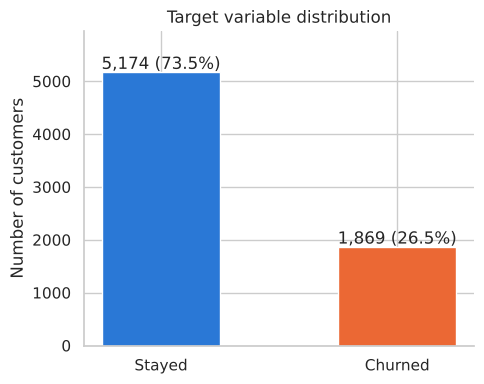

In [9]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"customers": counts, "percent": pct.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Stayed", "Churned"], [counts["No"], counts["Yes"]], color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate([counts["No"], counts["Yes"]]):
    ax.text(i, v + 60, f"{v:,} ({v / len(df) * 100:.1f}%)", ha="center")
ax.set_ylabel("Number of customers")
ax.set_title("Target variable distribution")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

73.5 percent of customers stayed and 26.5 percent churned, a moderate class imbalance. A model could predict "stay" for everyone and still score about 73 percent accuracy while catching no churners, so accuracy alone cannot be trusted here.

## 5. Exploratory Data Analysis

### 5.1 Descriptive statistics

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [11]:
df[[c for c in df.columns if c != 'customerID']].describe(exclude='number')

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


`TotalCharges` has a mean (2,280) well above its median (1,395), which signals a right-skewed distribution. The minimum of 0 is the 11 customers filled in during cleaning.

### 5.2 Distributions of numeric variables

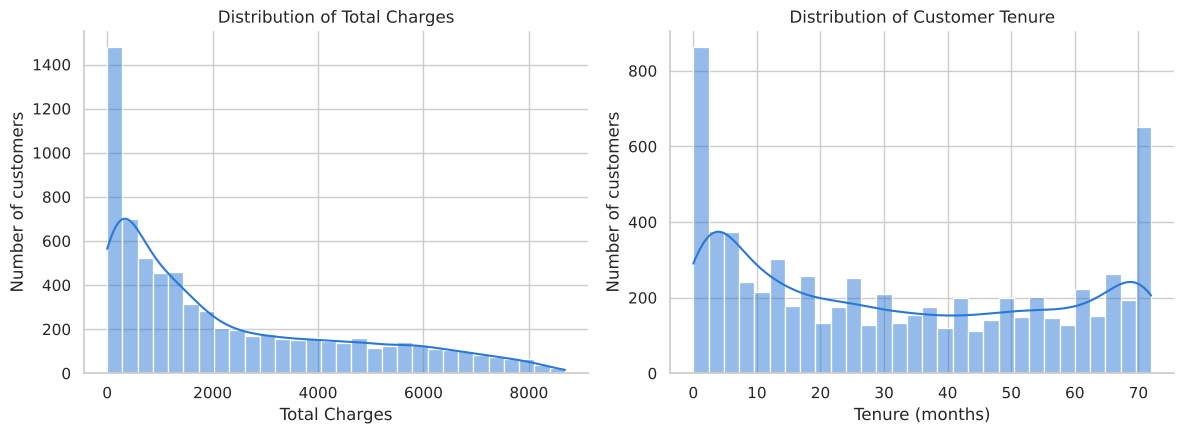

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["TotalCharges"], bins=30, kde=True, color=BLUE, ax=axes[0])
axes[0].set(title="Distribution of Total Charges", xlabel="Total Charges", ylabel="Number of customers")
sns.histplot(df["tenure"], bins=30, kde=True, color=BLUE, ax=axes[1])
axes[1].set(title="Distribution of Customer Tenure", xlabel="Tenure (months)", ylabel="Number of customers")
plt.tight_layout()
plt.show()

`TotalCharges` is right-skewed, with a long tail of high-value long-tenure customers. `tenure` has two peaks: many brand-new customers near 0 months and many long-standing customers near 72 months.

### 5.3 Churn patterns

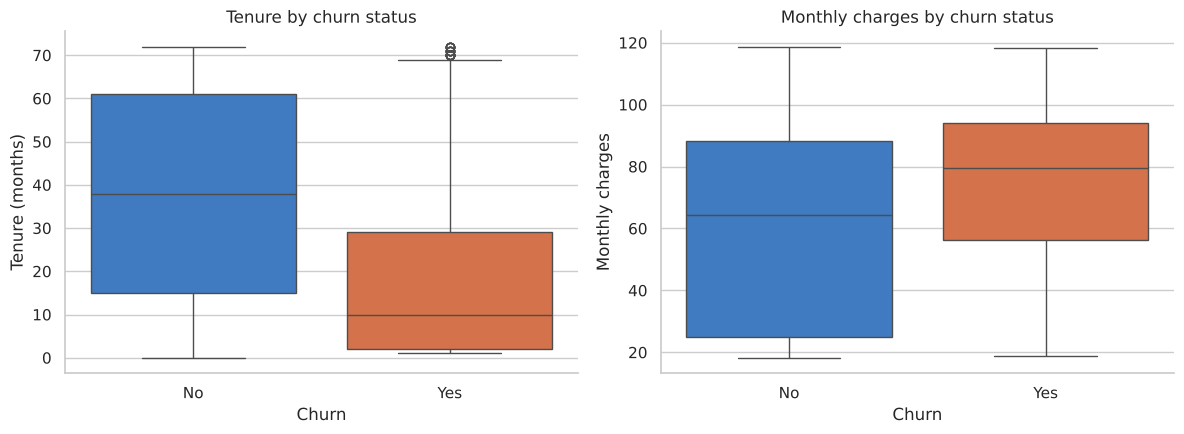

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="Churn", y="tenure", palette=PALETTE, order=["No", "Yes"], ax=axes[0])
axes[0].set(title="Tenure by churn status", xlabel="Churn", ylabel="Tenure (months)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=PALETTE, order=["No", "Yes"], ax=axes[1])
axes[1].set(title="Monthly charges by churn status", xlabel="Churn", ylabel="Monthly charges")
plt.tight_layout()
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

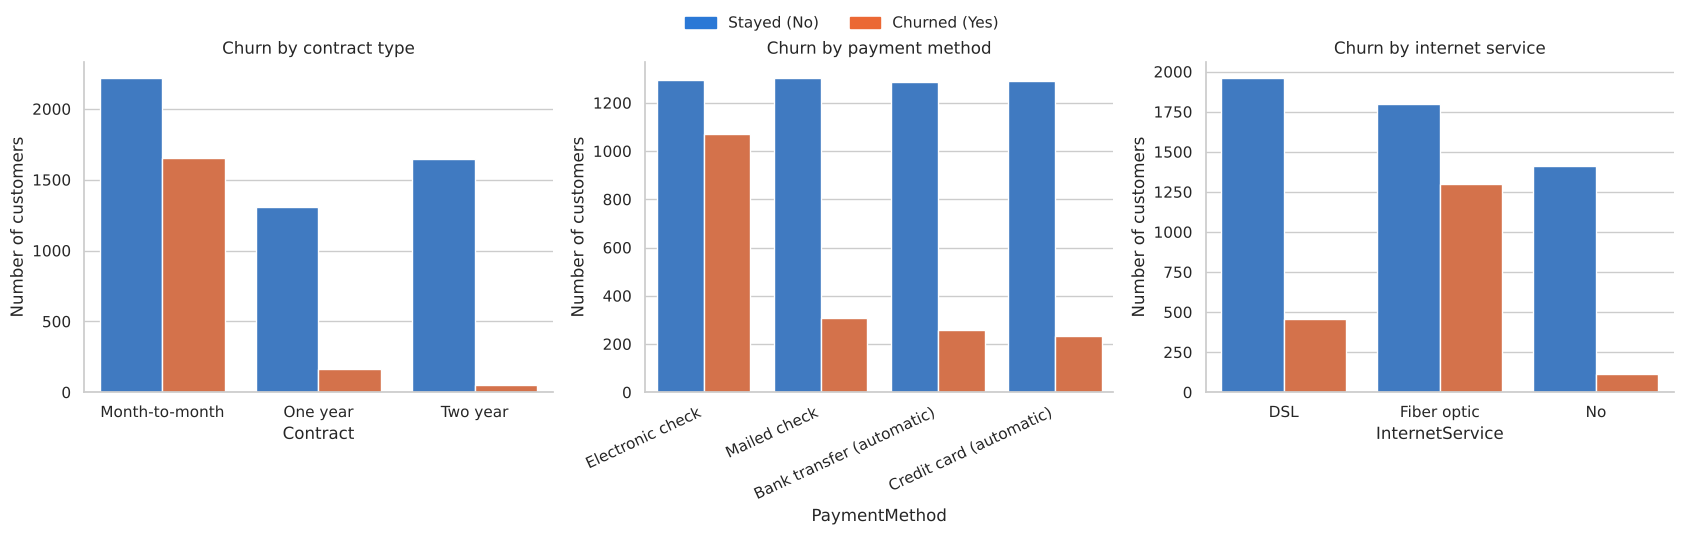

Churn             No   Yes  customers
Contract                             
Month-to-month  57.3  42.7       3875
One year        88.7  11.3       1473
Two year        97.2   2.8       1695 

Churn                        No   Yes  customers
PaymentMethod                                   
Bank transfer (automatic)  83.3  16.7       1544
Credit card (automatic)    84.8  15.2       1522
Electronic check           54.7  45.3       2365
Mailed check               80.9  19.1       1612 

Churn              No   Yes  customers
InternetService                       
DSL              81.0  19.0       2421
Fiber optic      58.1  41.9       3096
No               92.6   7.4       1526 



In [14]:
def churn_rate_table(col):
    t = (df.groupby(col)["Churn"].value_counts(normalize=True).mul(100)
           .unstack().fillna(0).round(1))
    t["customers"] = df[col].value_counts()
    return t

def churn_countplot(col, title, ax, rotate=0, legend=True):
    sns.countplot(data=df, x=col, hue="Churn", palette=PALETTE, hue_order=["No", "Yes"], ax=ax)
    ax.set(title=title, xlabel=col, ylabel="Number of customers")
    if rotate:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=rotate, ha="right")
    if not legend:
        ax.get_legend().remove()

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
churn_countplot("Contract", "Churn by contract type", axes[0], legend=False)
churn_countplot("PaymentMethod", "Churn by payment method", axes[1], rotate=25, legend=False)
churn_countplot("InternetService", "Churn by internet service", axes[2], legend=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)]
fig.legend(handles, ["Stayed (No)", "Churned (Yes)"], loc="upper center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.savefig(VISUALS + "churn_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

for col in ["Contract", "PaymentMethod", "InternetService"]:
    print(churn_rate_table(col), "\n")

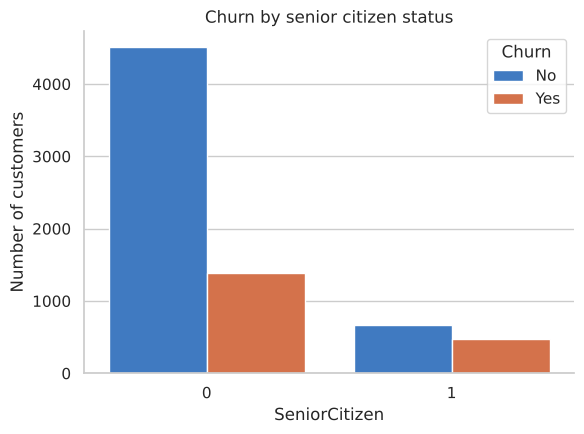

Churn            No   Yes  customers
SeniorCitizen                       
0              76.4  23.6       5901
1              58.3  41.7       1142


In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
churn_countplot("SeniorCitizen", "Churn by senior citizen status", ax)
plt.tight_layout()
plt.show()
print(churn_rate_table("SeniorCitizen"))

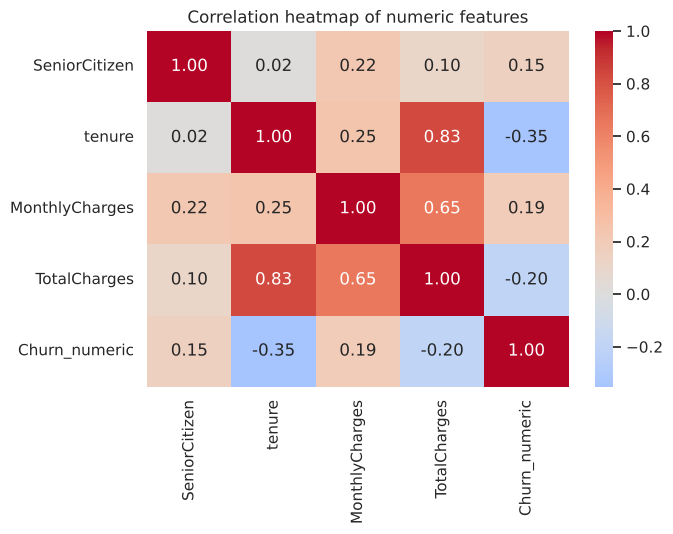

In [16]:
df["Churn_numeric"] = df["Churn"].map({"No": 0, "Yes": 1})
num_cols_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_numeric"]

plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols_corr].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.show()

df = df.drop(columns=["Churn_numeric"])

### 5.4 Key insights

1. **Tenure and churn.** Median tenure is about 10 months for churned customers versus 38 months for customers who stayed, so newer customers are far more likely to leave.
2. **Contract type and churn.** Month-to-month customers churn at 42.7 percent, versus 11.3 percent for one-year and 2.8 percent for two-year contracts. Contract type is one of the strongest churn drivers.
3. **Payment method and churn.** Electronic check users churn at 45.3 percent, more than double bank transfer (16.7 percent), credit card (15.2 percent) and mailed check (19.1 percent). Manual, non-automatic payment may add recurring friction.
4. **Monthly charges and churn.** Churned customers have a higher median monthly charge (79.65) than customers who stayed (64.43).
5. **Internet service and churn.** Fiber optic customers churn at 41.9 percent, versus 19.0 percent for DSL and 7.4 percent for customers with no internet service.
6. **Numeric correlations.** Tenure has the strongest correlation with churn (-0.35). MonthlyCharges (0.19) and TotalCharges (-0.20) are weaker. Tenure and TotalCharges are highly correlated with each other (0.83), which matters for modeling.
7. **Senior citizens and churn.** Senior citizens churn at 41.7 percent versus 23.6 percent for other customers, nearly double, even though the correlation coefficient is small (0.15).
8. **Number of services and churn.** The median number of subscribed services is the same (3) for churned and non-churned customers, so raw service count is not a strong standalone predictor (see section 6).

## 6. Feature Engineering

Three features were created.

| Feature | How it was created | Why it may help |
|---|---|---|
| `NumServices` | Count of "Yes" across PhoneService, MultipleLines, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies (0 to 8) | Summarizes how embedded a customer is across the product range |
| `TenureGroup` | `tenure` bucketed into 0-12, 13-24, 25-48 and 49-72 months | Churn falls sharply with tenure, and groups let models use the pattern directly |
| `HasInternetService` | Yes unless `InternetService` is "No" | Customers without internet churn far less (7.4 percent), separate from the type of internet |

In [17]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1)


def tenure_group(t):
    if t <= 12:
        return "0-12 months"
    elif t <= 24:
        return "13-24 months"
    elif t <= 48:
        return "25-48 months"
    return "49-72 months"


df["TenureGroup"] = df["tenure"].apply(tenure_group)
df["HasInternetService"] = df["InternetService"].apply(lambda x: "No" if x == "No" else "Yes")

df[["tenure", "TenureGroup", "InternetService", "HasInternetService", "NumServices"]].head(10)

,tenure,TenureGroup,InternetService,HasInternetService,NumServices
0,1,0-12 months,DSL,Yes,1
1,34,25-48 months,DSL,Yes,3
2,2,0-12 months,DSL,Yes,3
3,45,25-48 months,DSL,Yes,3
4,2,0-12 months,Fiber optic,Yes,1
5,8,0-12 months,Fiber optic,Yes,5
6,22,13-24 months,Fiber optic,Yes,4
7,10,0-12 months,DSL,Yes,1
8,28,25-48 months,Fiber optic,Yes,6
9,62,49-72 months,DSL,Yes,3


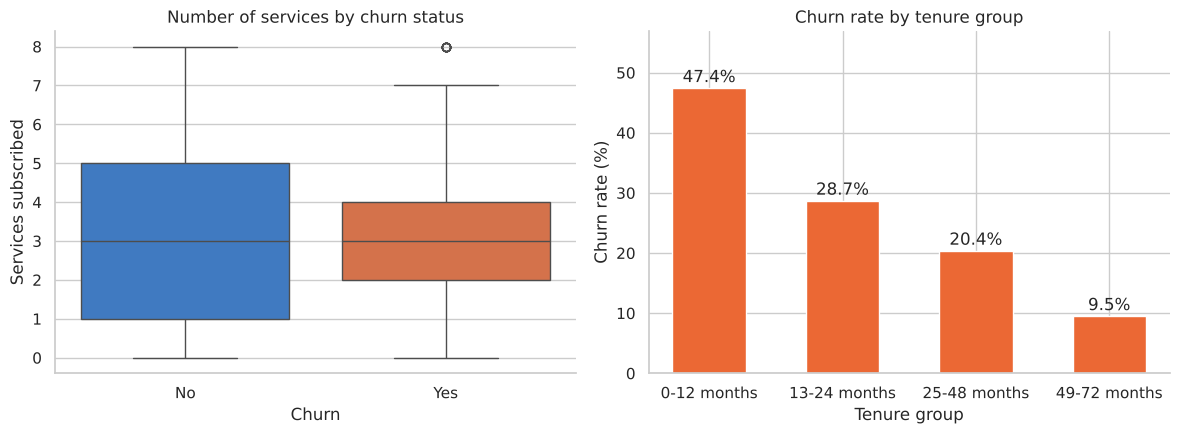

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="Churn", y="NumServices", palette=PALETTE, order=["No", "Yes"], ax=axes[0])
axes[0].set(title="Number of services by churn status", xlabel="Churn", ylabel="Services subscribed")

order = ["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
tg = (df.groupby("TenureGroup")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)).reindex(order)
axes[1].bar(order, tg.values, color=ORANGE, width=0.55)
for i, v in enumerate(tg.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set(title="Churn rate by tenure group", xlabel="Tenure group", ylabel="Churn rate (%)", ylim=(0, tg.max() * 1.2))
plt.tight_layout()
plt.show()

`NumServices` has the same median for both groups, so on its own it is a weak predictor. `TenureGroup` shows the steep fall in churn as customers stay longer.

## 7. Data Preprocessing

Steps: drop `customerID` (identifier, no predictive value), separate features from the target, one-hot encode categorical variables (`drop_first=True` to avoid redundant columns), and scale the numeric features so none dominates by size.

The target is encoded as 0 (stayed) and 1 (churned) throughout the rest of the notebook.

Note: scaling is applied before the train-test split here, to stay identical to the preprocessing used in the weekly notebooks so all reported numbers are comparable. Scaling after the split would be slightly stricter, and is listed as a possible improvement.

In [19]:
df_model = df.drop(columns=["customerID"])
y = df_model["Churn"].map({"No": 0, "Yes": 1})
X = df_model.drop(columns=["Churn"])

X = pd.get_dummies(X, drop_first=True)

num_features = ["tenure", "MonthlyCharges", "TotalCharges", "NumServices"]
X[num_features] = StandardScaler().fit_transform(X[num_features])

print("Feature matrix shape:", X.shape)
print("Non-numeric columns left:", X.select_dtypes(exclude=["number", "bool"]).shape[1])
print("Target balance:", y.value_counts().to_dict())
X.head()

Feature matrix shape: (7043, 35)
Non-numeric columns left: 0
Target balance: {0: 5174, 1: 1869}


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,NumServices,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24 months,TenureGroup_25-48 months,TenureGroup_49-72 months,HasInternetService_Yes
0,0,-1.277445,-1.160323,-0.992611,-1.145997,False,True,False,False,True,...,False,False,True,False,True,False,False,False,False,True
1,0,0.066327,-0.259629,-0.172165,-0.176011,True,False,False,True,False,...,True,False,False,False,False,True,False,True,False,True
2,0,-1.236724,-0.362660,-0.958066,-0.176011,True,False,False,True,False,...,False,False,True,False,False,True,False,False,False,True
3,0,0.514251,-0.746535,-0.193672,-0.176011,True,False,False,False,True,...,True,False,False,False,False,False,False,True,False,True
4,0,-1.236724,0.197365,-0.938874,-1.145997,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,True


In [20]:
ml_ready = X.copy()
ml_ready["Churn"] = df_model["Churn"].values
ml_ready.to_csv("../data/processed_data/telco_churn_ml_ready.csv", index=False)
print("Saved ml-ready dataset:", ml_ready.shape)

Saved ml-ready dataset: (7043, 36)


## 8. Model Development

A stratified 80/20 split keeps the 73.5 / 26.5 churn ratio in both sets. Three models are trained with default settings: Logistic Regression (baseline), Decision Tree, and Random Forest.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn share in train:", round(y_train.mean(), 4), "| in test:", round(y_test.mean(), 4))

Train: (5634, 35) | Test: (1409, 35)
Churn share in train: 0.2654 | in test: 0.2654


In [22]:
lr_default = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train, y_train)
dt_default = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
rf_default = RandomForestClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
print("Three baseline models trained.")

Three baseline models trained.


## 9. Model Evaluation

Metrics in the churn context:

- **Accuracy:** share of all predictions that are correct. Misleading here because of the imbalance.
- **Precision:** of customers flagged as churners, the share who really churned.
- **Recall:** of customers who really churned, the share the model caught.
- **F1-score:** the balance between precision and recall.
- **ROC-AUC:** how well the model ranks churners above non-churners across all thresholds.

In [23]:
def evaluate(name, model, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte
    yte = y_test if yte is None else yte
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    cm = confusion_matrix(yte, pred)
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(yte, pred), 4),
        "Precision": round(precision_score(yte, pred), 4),
        "Recall": round(recall_score(yte, pred), 4),
        "F1-Score": round(f1_score(yte, pred), 4),
        "ROC-AUC": round(roc_auc_score(yte, proba), 4),
        "FN": int(cm[1, 0]),
        "FP": int(cm[0, 1]),
    }


week3_table = pd.DataFrame([
    evaluate("Logistic Regression", lr_default),
    evaluate("Decision Tree", dt_default),
    evaluate("Random Forest", rf_default),
])
week3_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FN,FP
0,Logistic Regression,0.7999,0.6554,0.5187,0.5791,0.8424,180,102
1,Decision Tree,0.7360,0.5028,0.4733,0.4876,0.6516,197,175
2,Random Forest,0.7850,0.6263,0.4706,0.5374,0.8182,198,105


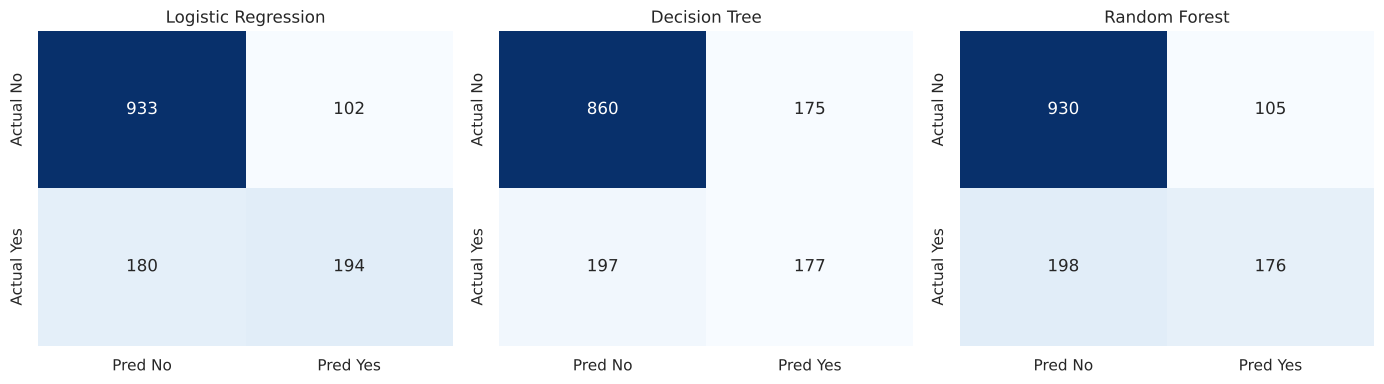

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, [("Logistic Regression", lr_default),
                                ("Decision Tree", dt_default),
                                ("Random Forest", rf_default)]):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"])
    ax.set_title(name)
plt.tight_layout()
plt.show()

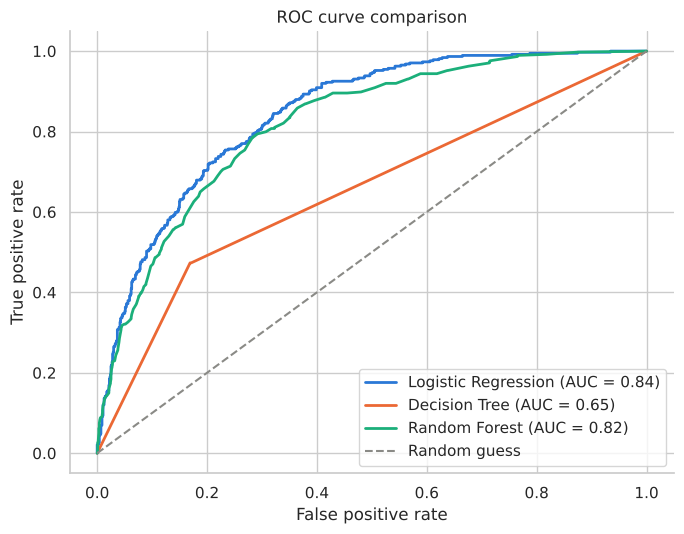

In [25]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for (name, m), color in zip([("Logistic Regression", lr_default),
                             ("Decision Tree", dt_default),
                             ("Random Forest", rf_default)],
                            [BLUE, ORANGE, "#1baf7a"]):
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.2f})")
ax.plot([0, 1], [0, 1], "--", color="#8a8a86", lw=1.5, label="Random guess")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(VISUALS + "model_performance.png", dpi=150, bbox_inches="tight")
plt.show()

### Initial model selection

Logistic Regression is selected as the initial model. It has the highest recall, F1-score and ROC-AUC of the three. Accuracy alone is not enough because the dataset contains substantially more non-churners than churners. The default Decision Tree has a much lower ROC-AUC, which points to overfitting (it memorizes the training data and generalizes poorly). Random Forest corrects most of that but still trails Logistic Regression.

This is an initial selection, not the final model. Imbalance handling, cross-validation and tuning in the next sections could change the comparison.

## 10. Class Imbalance Handling

### 10.1 How imbalanced is the data?

In [26]:
train_counts = y_train.value_counts()
print(train_counts.rename({0: "No (stayed)", 1: "Yes (churned)"}))
print("Imbalance ratio:", round(train_counts[0] / train_counts[1], 2), "non-churners per churner")

Churn
No (stayed)      4139
Yes (churned)    1495
Name: count, dtype: int64
Imbalance ratio: 2.77 non-churners per churner


The majority class is non-churners, at about 2.77 per churner. During training a model is rewarded for getting most rows right, so predicting "stay" is the easy way to score well and the minority class is under-learned. This is why the default models had recall of only 47 to 52 percent: they missed about half of the customers who actually left.

### 10.2 Techniques compared

Three approaches are tested on Logistic Regression and one on Random Forest, always evaluated on the untouched test set.

- **Class weighting:** a mistake on a churner costs more during training, in proportion to how rare churners are. The data is unchanged.
- **SMOTE oversampling:** creates synthetic churner rows in the training set only, until the classes are equal. The test set is never resampled, because it must represent real customers.

In [27]:
lr_balanced = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                 class_weight="balanced").fit(X_train, y_train)
rf_balanced = RandomForestClassifier(random_state=RANDOM_STATE,
                                     class_weight="balanced").fit(X_train, y_train)

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("After SMOTE:", y_train_sm.value_counts().to_dict())
lr_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_sm, y_train_sm)

imbalance_table = pd.DataFrame([
    evaluate("LR baseline", lr_default),
    evaluate("LR class weighted", lr_balanced),
    evaluate("LR SMOTE", lr_smote),
    evaluate("RF baseline", rf_default),
    evaluate("RF class weighted", rf_balanced),
])
imbalance_table

After SMOTE: {0: 4139, 1: 4139}


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FN,FP
0,LR baseline,0.7999,0.6554,0.5187,0.5791,0.8424,180,102
1,LR class weighted,0.7324,0.4975,0.7914,0.6109,0.8421,78,299
2,LR SMOTE,0.7580,0.5343,0.6872,0.6012,0.8286,117,224
3,RF baseline,0.7850,0.6263,0.4706,0.5374,0.8182,198,105
4,RF class weighted,0.7644,0.5479,0.6417,0.5911,0.8221,134,198


**Impact (Logistic Regression):**

- **Class weighting** raised recall from about 52 percent to about 79 percent and F1 from 0.579 to 0.611. Precision and accuracy fell, because the model now flags more customers. ROC-AUC was unchanged, which shows weighting moved the decision threshold, not the model's ability to rank customers.
- **SMOTE** gave a milder correction (recall about 69 percent) and slightly reduced ROC-AUC, since synthetic rows blur the training data.
- **Random Forest** also gained recall (47 to 64 percent) from weighting, but less than Logistic Regression.

Class weighting is kept for Logistic Regression: it has the highest recall and F1, keeps ROC-AUC intact, and needs no synthetic data. The trade-off is more false alarms. Missing a churner (losing the customer) costs more than an unnecessary retention offer, so the trade is worth making.

## 11. Hyperparameter Tuning

### 11.1 Cross-validation

Every result so far comes from a single split. 5-fold stratified cross-validation repeats the evaluation on five different splits to check that the result is consistent.

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]


def cv_report(name, model):
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    print(name)
    for m in scoring:
        s = res[f"test_{m}"]
        print(f"  {m:10s} folds={np.round(s, 3)}  mean={s.mean():.3f}  std={s.std():.3f}")
    print()
    return {m: (res[f"test_{m}"].mean(), res[f"test_{m}"].std()) for m in scoring}


cv_lr = cv_report("Logistic Regression (class weighted)",
                  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"))

Logistic Regression (class weighted)
  accuracy   folds=[0.754 0.74  0.754 0.733 0.746]  mean=0.745  std=0.008
  precision  folds=[0.523 0.506 0.524 0.497 0.514]  mean=0.513  std=0.010
  recall     folds=[0.826 0.813 0.807 0.767 0.797]  mean=0.802  std=0.020
  f1         folds=[0.64  0.624 0.636 0.603 0.625]  mean=0.626  std=0.013
  roc_auc    folds=[0.855 0.846 0.861 0.827 0.839]  mean=0.846  std=0.012



The five folds are consistent: recall stays between roughly 0.77 and 0.83, and ROC-AUC between 0.83 and 0.86, with small standard deviations. The single-split result was not luck.

### 11.2 Decision Tree: GridSearchCV

A grid search tries every combination in a grid with cross-validation, on the training set only. F1 is the scoring metric because accuracy would reward predicting "stay" for everyone. Limiting depth and leaf size directly addresses the overfitting seen earlier.

In [29]:
dt_params = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [10, 20, 50],
    "min_samples_split": [2, 20, 50],
}
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    dt_params, cv=5, scoring="f1", n_jobs=-1)
dt_grid.fit(X_train, y_train)

print("Best params:", dt_grid.best_params_)
print("Best CV F1:", round(dt_grid.best_score_, 3))
best_dt = dt_grid.best_estimator_
pd.DataFrame([evaluate("Decision Tree (default)", dt_default),
              evaluate("Decision Tree (tuned)", best_dt)])

Best params: {'max_depth': 7, 'min_samples_leaf': 50, 'min_samples_split': 2}
Best CV F1: 0.629


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FN,FP
0,Decision Tree (default),0.7360,0.5028,0.4733,0.4876,0.6516,197,175
1,Decision Tree (tuned),0.7424,0.5092,0.8102,0.6254,0.8375,71,292


### 11.3 Random Forest: RandomizedSearchCV

A full grid is slow for a forest, so 15 random combinations are sampled instead. Only 15 of 72 combinations are tried, so a slightly better setting may exist.

In [30]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 8, 12, None],
    "min_samples_leaf": [5, 10, 20],
    "max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    rf_params, n_iter=15, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 3))
best_rf = rf_search.best_estimator_
pd.DataFrame([evaluate("Random Forest (default)", rf_default),
              evaluate("Random Forest (class weighted)", rf_balanced),
              evaluate("Random Forest (tuned)", best_rf)])

Best params: {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
Best CV F1: 0.634


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FN,FP
0,Random Forest (default),0.7850,0.6263,0.4706,0.5374,0.8182,198,105
1,Random Forest (class weighted),0.7644,0.5479,0.6417,0.5911,0.8221,134,198
2,Random Forest (tuned),0.7530,0.5233,0.7807,0.6266,0.8418,82,266


### 11.4 Cross-validation of the tuned models

In [31]:
cv_rf = cv_report("Random Forest (tuned)", best_rf)
cv_dt = cv_report("Decision Tree (tuned)", best_dt)

Random Forest (tuned)
  accuracy   folds=[0.77  0.749 0.779 0.75  0.755]  mean=0.760  std=0.012
  precision  folds=[0.546 0.518 0.559 0.52  0.528]  mean=0.534  std=0.016
  recall     folds=[0.786 0.759 0.781 0.745 0.735]  mean=0.761  std=0.020
  f1         folds=[0.645 0.616 0.652 0.612 0.615]  mean=0.628  std=0.017
  roc_auc    folds=[0.859 0.838 0.857 0.825 0.839]  mean=0.844  std=0.013



Decision Tree (tuned)
  accuracy   folds=[0.74  0.715 0.754 0.728 0.747]  mean=0.737  std=0.014
  precision  folds=[0.506 0.478 0.524 0.492 0.516]  mean=0.503  std=0.017
  recall     folds=[0.837 0.81  0.802 0.791 0.778]  mean=0.804  std=0.020
  f1         folds=[0.631 0.601 0.634 0.606 0.62 ]  mean=0.619  std=0.013
  roc_auc    folds=[0.841 0.833 0.835 0.818 0.833]  mean=0.832  std=0.008



## 12. Final Model Selection

### 12.1 Test-set comparison

In [32]:
final_table = pd.DataFrame([
    evaluate("Logistic Regression (baseline)", lr_default),
    evaluate("Logistic Regression (class weighted)", lr_balanced),
    evaluate("Decision Tree (tuned)", best_dt),
    evaluate("Random Forest (tuned)", best_rf),
])
final_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FN,FP
0,Logistic Regression (baseline),0.7999,0.6554,0.5187,0.5791,0.8424,180,102
1,Logistic Regression (class weighted),0.7324,0.4975,0.7914,0.6109,0.8421,78,299
2,Decision Tree (tuned),0.7424,0.5092,0.8102,0.6254,0.8375,71,292
3,Random Forest (tuned),0.7530,0.5233,0.7807,0.6266,0.8418,82,266


In [33]:
cv_summary = pd.DataFrame({
    "Model": ["Logistic Regression (class weighted)", "Decision Tree (tuned)", "Random Forest (tuned)"],
    "CV Recall": [f"{r['recall'][0]:.3f} (+/- {r['recall'][1]:.3f})" for r in (cv_lr, cv_dt, cv_rf)],
    "CV F1": [f"{r['f1'][0]:.3f} (+/- {r['f1'][1]:.3f})" for r in (cv_lr, cv_dt, cv_rf)],
    "CV ROC-AUC": [f"{r['roc_auc'][0]:.3f} (+/- {r['roc_auc'][1]:.3f})" for r in (cv_lr, cv_dt, cv_rf)],
})
cv_summary

,Model,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression (class weighted),0.802 (+/- 0.020),0.626 (+/- 0.013),0.846 (+/- 0.012)
1,Decision Tree (tuned),0.804 (+/- 0.020),0.619 (+/- 0.013),0.832 (+/- 0.008)
2,Random Forest (tuned),0.761 (+/- 0.020),0.628 (+/- 0.017),0.844 (+/- 0.013)


**Selected model: Logistic Regression (class weighted).**

Logistic Regression achieved a mean cross-validated recall of 80.2% and a mean ROC-AUC of 84.6%, compared with Random Forest's 76.1% and 84.4%. Random Forest had a slightly higher F1-score (62.8% versus 62.6%), but this difference is insignificant, and both models showed similar reliability across the validation folds.

Recall is the deciding metric against Random Forest. A missed churner is the most costly error for the business, and the recall gap of about 4 points is roughly two standard deviations in cross-validation, which is large enough to matter.

The tuned Decision Tree matched Logistic Regression on cross-validated recall (80.4% versus 80.2%), but it had the lowest F1-score (61.9%), the lowest ROC-AUC (83.2%) and the lowest precision (50.3%) of the three finalists, so it produces more false alarms for no gain in recall. It was therefore not selected.

In terms of commercial applicability, Logistic Regression is cheaper to run and easier to explain than Random Forest. Its coefficients show which customer characteristics increase or decrease churn risk, which supports the feature importance analysis and business recommendations in the following sections.

## 13. Feature Importance

Logistic Regression coefficients show the direction and size of each feature's association with churn. A positive coefficient raises predicted churn risk, a negative one lowers it. Numeric features are scaled and the rest are 0/1 flags, so the sizes are roughly comparable.

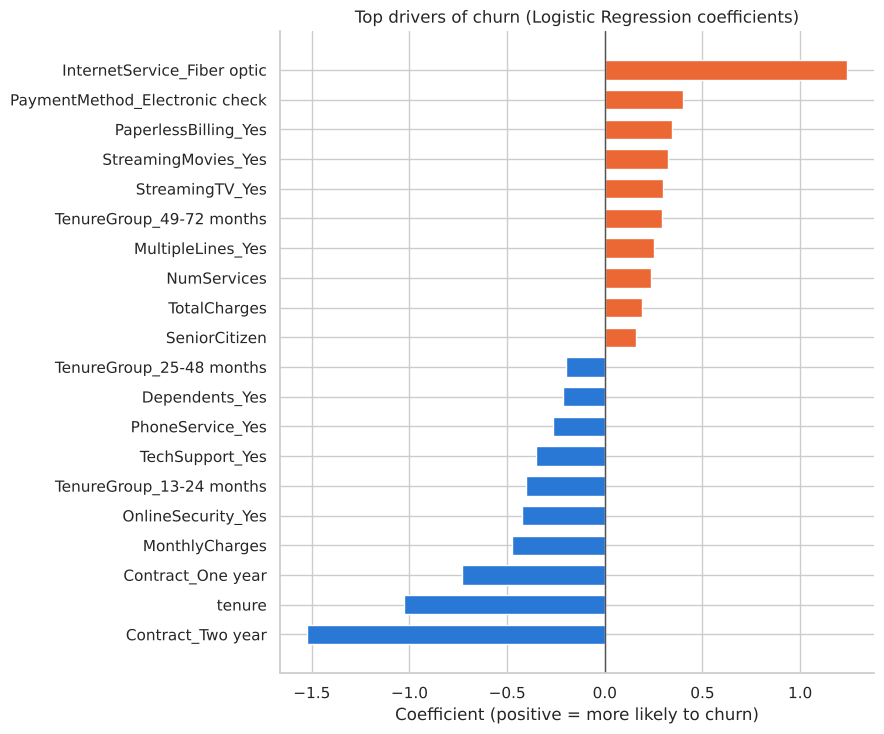

Strongest increase in churn risk:
 InternetService_Fiber optic       1.240
PaymentMethod_Electronic check    0.400
PaperlessBilling_Yes              0.346
StreamingMovies_Yes               0.323
StreamingTV_Yes                   0.300
TenureGroup_49-72 months          0.294
MultipleLines_Yes                 0.251
NumServices                       0.238
dtype: float64

Strongest decrease in churn risk:
 Contract_Two year          -1.525
tenure                     -1.028
Contract_One year          -0.731
MonthlyCharges             -0.477
OnlineSecurity_Yes         -0.424
TenureGroup_13-24 months   -0.404
TechSupport_Yes            -0.351
PhoneService_Yes           -0.267
dtype: float64


In [34]:
final_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                 class_weight="balanced").fit(X_train, y_train)
coefs = pd.Series(final_model.coef_[0], index=X.columns).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index, top.values, color=[BLUE if v < 0 else ORANGE for v in top.values], height=0.65)
ax.axvline(0, color="#52514e", lw=1)
ax.set(title="Top drivers of churn (Logistic Regression coefficients)",
       xlabel="Coefficient (positive = more likely to churn)")
plt.tight_layout()
plt.savefig(VISUALS + "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Strongest increase in churn risk:\n", coefs.tail(8)[::-1].round(3))
print("\nStrongest decrease in churn risk:\n", coefs.head(8).round(3))

**Strongest predictors.** By size, the largest coefficients are Contract_Two year (-1.52), InternetService_Fiber optic (+1.24), tenure (-1.03) and Contract_One year (-0.73). Contract length and fiber optic internet are the two biggest drivers. Electronic check (+0.40) and paperless billing (+0.35) follow among the factors that raise risk.

**High-risk characteristics.** Customers on fiber optic internet, paying by electronic check, using paperless billing, streaming services or multiple phone lines show higher churn risk. These are associations, not proof of cause.

**Services and contracts.** Month-to-month is the reference category, so one-year and two-year contracts have negative coefficients, especially two-year. Online security (-0.42) and tech support (-0.35) are also negative, meaning customers with these services are less likely to churn.

**Agreement with the EDA.** The model confirms the EDA findings on contract type, fiber optic, electronic check and tenure.

**Caution.** MonthlyCharges (-0.48) and TenureGroup_49-72 months (+0.29) look like they contradict the EDA. This is a collinearity effect, because fiber and streaming already capture price, and tenure overlaps with TenureGroup and TotalCharges. Coefficients for overlapping features should not be read in isolation.

## 14. Business Insights

### 14.1 Final model evaluation

The final model is the class-weighted Logistic Regression, evaluated on the held-out test set.

Accuracy : 0.7324
Precision: 0.4975
Recall   : 0.7914
F1-score : 0.6109
ROC-AUC  : 0.8421


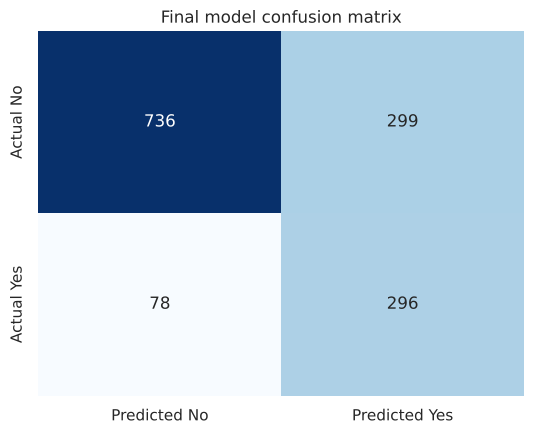

In [35]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted No", "Predicted Yes"], yticklabels=["Actual No", "Actual Yes"])
plt.title("Final model confusion matrix")
plt.tight_layout()
plt.savefig(VISUALS + "final_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

- **Accuracy (73.2%):** Out of every 100 customers, the model's prediction is correct for about 73.
- **Precision (49.7%):** Out of every 100 customers the model predicts will churn, about 50 really leave.
- **Recall (79.1%):** Out of every 100 customers who actually leave, the model catches about 79.
- **F1-score (61.1%):** The balance between precision and recall, reflecting the model's ability to identify churners while limiting false alarms.
- **ROC-AUC (84.2%):** If one customer who left and one who stayed are picked at random, the model gives the customer who left the higher risk score about 84% of the time.

### 14.2 Error analysis

In [36]:
results = X_test.copy()
results["actual"] = y_test.values
results["pred"] = y_pred

tp = results[(results.actual == 1) & (results.pred == 1)]
fn = results[(results.actual == 1) & (results.pred == 0)]
fp = results[(results.actual == 0) & (results.pred == 1)]
tn = results[(results.actual == 0) & (results.pred == 0)]
print("TP:", len(tp), "FN:", len(fn), "FP:", len(fp), "TN:", len(tn))

cols = ["tenure", "MonthlyCharges", "Contract_One year", "Contract_Two year",
        "PaymentMethod_Electronic check", "InternetService_Fiber optic"]
profile = pd.DataFrame({
    "Caught churners (TP)": tp[cols].mean(),
    "Missed churners (FN)": fn[cols].mean(),
    "False alarms (FP)": fp[cols].mean(),
}).round(2)
profile

TP: 296 FN: 78 FP: 299 TN: 736


,Caught churners (TP),Missed churners (FN),False alarms (FP)
tenure,-0.79,-0.09,-0.45
MonthlyCharges,0.38,-0.15,0.41
Contract_One year,0.03,0.35,0.09
Contract_Two year,0.00,0.12,0.00
PaymentMethod_Electronic check,0.63,0.24,0.55
InternetService_Fiber optic,0.77,0.31,0.70


Tenure and monthly charges are scaled, so a value near 0 means about average.

**Missed churners versus caught churners.** Missed churners have longer tenure and lower monthly charges than caught churners. They are more likely to be on one-year or two-year contracts and less likely to use electronic check or fiber optic internet. They look low-risk to the model, so their risk is underestimated.

**False alarms.** The false alarms look similar to the caught churners (fiber 0.70, electronic check 0.55). They are customers with a high-risk profile who stayed, which is why they are hard to avoid.

**Why each error matters.**

- **False negatives (78):** These customers leave without the business getting a chance to offer retention support, so the company loses the customer and their future revenue.
- **False positives (299):** These customers receive retention offers they did not need, which wastes resources that could target customers more likely to leave.

### 14.3 Does support service use relate to churn?

Among customers with internet service only, since customers without internet cannot have these services.

In [37]:
internet_df = df[df["HasInternetService"] == "Yes"]
for c in ["TechSupport", "OnlineSecurity"]:
    rate = internet_df.groupby(c)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).round(1)
    print(c, "-> churn rate (%):", rate.to_dict())

TechSupport -> churn rate (%): {'No': 41.6, 'Yes': 15.2}
OnlineSecurity -> churn rate (%): {'No': 41.8, 'Yes': 14.6}


## 15. Recommendations

These are based on this project's findings. They show association, not proven cause, so expected benefits are stated as likely rather than guaranteed.

1. **Encourage longer contracts.**
   - *Finding:* Churn is 42.7% on month-to-month contracts, versus 11.3% on one-year and 2.8% on two-year. Contract_Two year is the strongest coefficient in the model (-1.52).
   - *Action:* Offer discounts or perks to month-to-month customers who move to a one-year or two-year plan.
   - *Expected benefit:* Moving customers off month-to-month is likely to reduce churn in the group that currently leaves most.

2. **Move electronic check users to automatic payment.**
   - *Finding:* Electronic check customers churn at 45.3%, versus 15.2% to 19.1% for the other payment methods.
   - *Action:* Offer a small incentive to switch to bank transfer or credit card auto-pay.
   - *Expected benefit:* Removing the manual payment step may reduce the friction that is associated with leaving.

3. **Review fiber optic quality and pricing.**
   - *Finding:* Fiber optic customers churn at 41.9%, versus 19.0% for DSL, and fiber has the strongest positive coefficient (+1.24).
   - *Action:* Investigate service reliability and price competitiveness for fiber customers, and run satisfaction checks on this group.
   - *Expected benefit:* Fixing the cause of dissatisfaction in the highest-risk service tier could lower churn where it is concentrated.

4. **Launch an early onboarding program.**
   - *Finding:* Churned customers have a median tenure of about 10 months, versus about 38 for customers who stayed.
   - *Action:* Run check-ins, setup help and offers during the first 12 months.
   - *Expected benefit:* Supporting customers while they are still deciding whether to stay is likely to reduce early churn.

5. **Bundle tech support and online security.**
   - *Finding:* Among customers with internet service, churn is 15.2% for those with tech support versus 41.6% for those without, and 14.6% for those with online security versus 41.8% for those without. Both services also have negative model coefficients (-0.35 and -0.42).
   - *Action:* Offer a free trial or discounted bundle of these services to at-risk internet customers who do not have them.
   - *Expected benefit:* Customers who use these services may become more attached to the company. This needs testing, since customers who choose these services may already be more loyal, so the data shows association only.

6. **Give senior citizens targeted support.**
   - *Finding:* Senior citizens churn at 41.7%, versus 23.6% for other customers.
   - *Action:* Provide simpler plans, phone-based support and proactive outreach.
   - *Expected benefit:* Meeting this group's needs more directly may narrow the churn gap.

7. **Use the model to target retention spending.**
   - *Finding:* The model flags about 595 customers and catches 296 of the 374 who actually left, but half of its flags are false alarms.
   - *Action:* Rank customers by churn probability. Call only the top tier, send low-cost offers to the medium tier, and only monitor the low tier.
   - *Expected benefit:* Costly interventions go to the customers most likely to leave, which limits wasted offers.

## 16. Conclusion

This project built a model to predict which telecom customers are likely to churn. The data showed that churn is strongly associated with month-to-month contracts, short tenure, electronic check payments and fiber optic internet, while longer contracts and services such as tech support and online security are associated with lower churn.

The first models looked acceptable on accuracy but missed nearly half of the customers who left. After handling the class imbalance, the final class-weighted Logistic Regression model catches about 79% of churners (recall 0.79, ROC-AUC 0.84), and cross-validation showed the result is stable. The trade-off is that about half of its flags are false alarms, which is acceptable because losing a customer costs more than an unnecessary retention offer.

The main limitations are the model's precision of about 50% and that all findings show association, not proven cause. Scaling was applied before the train-test split, which could be tightened. Future work could tune the decision threshold using real intervention costs, test additional models such as XGBoost, and pilot the recommended retention actions to measure their effect.